# Borton Appendix B → is there mass-spectral data for **identification**?

For each compound reported in E&L studies (Borton & Coleman 2025, Appendix B), this notebook checks whether reference spectra exist that help **identify** it:

| Layer | What it supports | Source |
|---|---|---|
| EI library spectrum (+ Kovats RI) | GC-MS identification | MS-DIAL public EI library, `GCMS DB-Public-KovatsRI-VS3.msp` |
| LC-MS/MS positive spectra | LC-MS identification (ESI+) | MS-DIAL public MS/MS, `MSMS-Public_experimentspectra-pos-VS19.msp` |
| LC-MS/MS negative spectra | LC-MS identification (ESI−) | MS-DIAL public MS/MS, `MSMS-Public_all-neg-VS19.msp` |
| LC-MS/MS spectra | LC-MS identification | MassSpecGym (Hugging Face, MIT) |
| Measured RRF per method | **quantification** | FDA CLAP (shown for contrast) |

**Identification ≠ quantification.** A library spectrum helps confirm *what* a peak is; it says nothing about *how much* is there or how strongly the compound responds. The key output is the 2×2 table: *spectra for ID* vs *measured response (CLAP)*.

**Matching key:** first InChIKey block (14 characters, connectivity), the same key MassSpecGym uses.

**Not done here:** no spectra are compared and nothing is predicted. "Has a spectrum" means a reference exists; whether it would match a real extract depends on the instrument, the conditions and the sample.

## 0. Setup

In [1]:
%pip install -q pandas openpyxl matplotlib huggingface_hub
# optional: RDKit (InChIKeys from Stavitskaya SMILES) -> %pip install -q rdkit

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import re, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path(r"C:\Users\misak\Documents\Project\Hackathon")
ELCC    = PROJECT / "el-coverage-checker" / "data"
BORTON_CLEAN   = ELCC / "interim" / "borton_clean.csv"           # from step 02
BORTON_STRUCT  = ELCC / "interim" / "structures_borton.csv"      # from step 03 (PubChem), preferred if present
CLAP_STRUCT    = ELCC / "interim" / "structures_clap.csv"
CLAP_COMP      = ELCC / "interim" / "clap_compounds.csv"
PLASTCHEM      = (sorted(PROJECT.glob("plastchem_db_v*.xlsx")) or [None])[-1]
STAVITSKAYA    = PROJECT / "1-s2.0-S0273230026001364-mmc1.xlsx"
EI_MSP   = sorted(PROJECT.glob("GCMS*.msp"))      # EI library (GC-MS)
MSMS_MSP = sorted(PROJECT.glob("MSMS*.msp"))      # LC-MS/MS libraries, positive and negative (MS-DIAL public)
MSG_CACHE = PROJECT / "gcms_outputs" / "massspecgym_by_molecule.csv"   # written by the GC-MS notebook, reused here
USE_MSG = True
OUT = PROJECT / "ms_id_outputs"; OUT.mkdir(exist_ok=True)
print("EI:", [p.name for p in EI_MSP]); print("MS/MS:", [p.name for p in MSMS_MSP]); print("PlastChem:", PLASTCHEM)

EI: ['GCMS DB-Public-KovatsRI-VS3.msp']
MS/MS: ['MSMS-Public_all-neg-VS19.msp', 'MSMS-Public_experimentspectra-pos-VS19.msp']
PlastChem: C:\Users\misak\Documents\Project\Hackathon\plastchem_db_v1.01.xlsx


## 1. Borton → InChIKey
Order of preference:
1. **`structures_borton.csv` from pipeline step 03** (PubChem lookup by CAS, Velan's step). Most complete; used when present.
2. **CAS bridges** to datasets that already carry structures: CLAP, PlastChem (InChIKey) and Stavitskaya (SMILES → InChIKey, needs RDKit).

Bridges only cover Borton compounds that also appear in those datasets, so coverage below is a **lower bound** until step 03 has run. Rows without a valid CAS (about a third of Borton) need step 03 with `--name-fallback`.

In [3]:
b = pd.read_csv(BORTON_CLEAN, usecols=["borton_id", "name", "valid_cas", "n_valid_cas"])
ik1 = lambda s: s.astype("string").str.strip().str.split("-").str[0]

cas2ik = {}   # CAS -> (ik1, source); first source wins
def add(cas, iks, src):
    for c, k in zip(cas.astype(str).str.strip(), iks):
        if isinstance(k, str) and len(k) == 14 and c not in cas2ik:
            cas2ik[c] = (k, src)

cs, cc = pd.read_csv(CLAP_STRUCT), pd.read_csv(CLAP_COMP)
clap = cs[["clap_code", "inchikey_pubchem"]].merge(cc[["clap_code", "cas", "primary_name", "GCMS_POS_status", "LCMS_POS_status", "LCMS_NEG_status"]], on="clap_code")
clap["ik1"] = ik1(clap["inchikey_pubchem"]).astype(object)
add(clap["cas"], clap["ik1"], "CLAP")
if PLASTCHEM is not None:
    pc = pd.read_excel(PLASTCHEM, sheet_name="Full database", header=1, usecols=["cas", "inchikey"])
    add(pc["cas"], ik1(pc["inchikey"]).astype(object), "PlastChem")
if STAVITSKAYA.exists():
    try:
        from rdkit import Chem, RDLogger; RDLogger.DisableLog("rdApp.*")
        st = pd.read_excel(STAVITSKAYA)
        def smi2ik(s):
            m = Chem.MolFromSmiles(str(s)) if isinstance(s, str) else None
            return Chem.MolToInchiKey(m).split("-")[0] if m is not None else None
        add(st["Reported CAS"], st["SMILES"].map(smi2ik), "Stavitskaya")
    except ImportError:
        print("RDKit not installed: Stavitskaya bridge skipped")

def resolve(cas_field):
    if not isinstance(cas_field, str): return (None, None, False)
    hits = [cas2ik[c.strip()] for c in cas_field.split(";") if c.strip() in cas2ik]
    if not hits: return (None, None, False)
    return (hits[0][0], hits[0][1], len({h[0] for h in hits}) > 1)   # conflict if several CAS -> different structures

b[["ik1", "ik_source", "flag_cas_conflict"]] = pd.DataFrame(b["valid_cas"].map(resolve).tolist(), index=b.index)

if BORTON_STRUCT.exists():   # step 03 output takes priority
    s3 = pd.read_csv(BORTON_STRUCT)
    s3 = s3.dropna(subset=["inchikey_pubchem"])[["borton_id", "inchikey_pubchem"]]
    s3["ik_s3"] = ik1(s3["inchikey_pubchem"]).astype(object)
    b = b.merge(s3[["borton_id", "ik_s3"]], on="borton_id", how="left")
    use = b["ik_s3"].notna()
    b.loc[use, "ik1"] = b.loc[use, "ik_s3"]; b.loc[use, "ik_source"] = "PubChem (step 03)"
    b = b.drop(columns="ik_s3")
else:
    print("structures_borton.csv not found: using CAS bridges only (lower bound).")

print(f"Borton rows: {len(b)} | with valid CAS: {b['valid_cas'].notna().sum()} | with InChIKey: {b['ik1'].notna().sum()} "
      f"| unique structures: {b['ik1'].nunique()}")
print(b["ik_source"].value_counts(dropna=False).to_string())

RDKit not installed: Stavitskaya bridge skipped
structures_borton.csv not found: using CAS bridges only (lower bound).
Borton rows: 18266 | with valid CAS: 12242 | with InChIKey: 3551 | unique structures: 3165
ik_source
NaN          14715
PlastChem     3421
CLAP           130


## 2. Read the libraries (metadata only)
Only names, InChIKeys and method fields are read, not the peaks, so even the 270 MB MS/MS file reads in about a minute.

In [4]:
def msp_metadata(path, keys):
    recs, cur = [], {}
    with open(path, encoding="utf-8", errors="ignore") as f:
        for line in f:
            if not line.strip():
                if cur: recs.append(cur); cur = {}
                continue
            if line[0].isdigit():            # peak lines
                continue
            k, sep, v = line.partition(":")
            if not sep: continue
            k = k.strip().upper().replace(" ", "").replace("_", "")
            if k in keys: cur[keys[k]] = v.strip()
    if cur: recs.append(cur)
    d = pd.DataFrame(recs)
    d["ik1"] = d["inchikey"].astype("string").str.split("-").str[0]
    return d.dropna(subset=["ik1"])

join = lambda s: ", ".join(sorted({str(x) for x in s if pd.notna(x) and str(x)}))

ei = pd.concat([msp_metadata(p, {"NAME": "name", "INCHIKEY": "inchikey", "RETENTIONINDEX": "ri"}) for p in EI_MSP], ignore_index=True) if EI_MSP else pd.DataFrame(columns=["ik1", "ri", "name"])
ei["ri"] = pd.to_numeric(ei.get("ri"), errors="coerce").where(lambda r: r > 0)
ei_sum = ei.groupby("ik1").agg(ei_n_spectra=("ik1", "size"), ei_ri_median=("ri", "median"),
                               ei_name=("name", lambda s: s.iloc[0].split(";")[0])).reset_index()
print(f"EI library: {len(ei)} spectra, {len(ei_sum)} structures")

ms = pd.concat([msp_metadata(p, {"NAME": "name", "INCHIKEY": "inchikey", "PRECURSORTYPE": "adduct", "INSTRUMENTTYPE": "instrument",
                                 "IONIZATION": "ionization", "IONMODE": "ionmode", "COLLISIONENERGY": "ce"}) for p in MSMS_MSP],
               ignore_index=True) if MSMS_MSP else pd.DataFrame(columns=["ik1", "adduct", "instrument", "ionmode"])
ms["neg"] = ms["ionmode"].astype("string").str.lower().str.startswith("neg")
ms_sum = ms.groupby("ik1").agg(msms_n_spectra=("ik1", "size"), msms_pos_n=("neg", lambda s: int((~s).sum())),
                               msms_neg_n=("neg", lambda s: int(s.sum())), msms_adducts=("adduct", join),
                               msms_instruments=("instrument", join)).reset_index()
ms_sum[["msms_pos_n", "msms_neg_n"]] = ms_sum[["msms_pos_n", "msms_neg_n"]].replace(0, np.nan)
print(f"MS/MS library: {len(ms)} spectra, {len(ms_sum)} structures")
print(ms["ionmode"].value_counts().to_string())

EI library: 28220 spectra, 8546 structures
MS/MS library: 376342 spectra, 22101 structures
ionmode
Positive    322191
Negative     54151


## 3. MassSpecGym (optional)
Reuses the per-molecule cache written by the GC-MS notebook (section 9b). Otherwise it loads MassSpecGym (`massspecgym` package, or the TSV via `huggingface_hub`) and writes the same cache.

In [5]:
msg_sum = None
if USE_MSG and MSG_CACHE.exists():
    msg_sum = pd.read_csv(MSG_CACHE)
elif USE_MSG:
    try:
        try:
            from massspecgym.utils import load_massspecgym
            msg = load_massspecgym()
        except Exception as e:
            print(f"massspecgym package not usable ({type(e).__name__}); fetching the TSV via huggingface_hub")
            from huggingface_hub import HfApi, hf_hub_download
            repo = "roman-bushuiev/MassSpecGym"
            tsv = [f for f in HfApi().list_repo_files(repo, repo_type="dataset") if f.endswith("MassSpecGym.tsv")][0]
            msg = pd.read_csv(hf_hub_download(repo, tsv, repo_type="dataset"), sep="\t",
                              usecols=lambda c: c not in ("mzs", "intensities"))
        print(msg["adduct"].value_counts().to_string())
        msg_sum = (msg.groupby("inchikey").agg(msg_n_spectra=("identifier", "size"), msg_adducts=("adduct", join),
                                               msg_instruments=("instrument_type", join), msg_smiles=("smiles", "first"))
                   .reset_index().rename(columns={"inchikey": "ik1"}))
        MSG_CACHE.parent.mkdir(exist_ok=True); msg_sum.to_csv(MSG_CACHE, index=False); del msg
    except Exception as e:
        print(f"MassSpecGym not loaded ({type(e).__name__}: {e}); continuing without it.")
print("MassSpecGym molecules:", None if msg_sum is None else len(msg_sum))

MassSpecGym molecules: 28929


## 4. Join and classify each Borton compound

In [6]:
t = b.merge(ei_sum, on="ik1", how="left").merge(ms_sum, on="ik1", how="left")
if msg_sum is not None:
    t = t.merge(msg_sum.drop(columns=[c for c in ["msg_smiles"] if c in msg_sum]), on="ik1", how="left")
else:
    t["msg_n_spectra"] = np.nan
clap_k = clap.dropna(subset=["ik1"]).drop_duplicates("ik1")[["ik1", "clap_code", "GCMS_POS_status", "LCMS_POS_status", "LCMS_NEG_status"]]
t = t.merge(clap_k, on="ik1", how="left")

t["id_GC_EI"]    = t["ei_n_spectra"].notna()
t["id_GC_EI_RI"] = t["ei_ri_median"].notna()
t["id_LC_pos"]   = t["msms_pos_n"].notna() | t["msg_n_spectra"].notna()   # MassSpecGym: check its adducts (mostly positive)
t["id_LC_neg"]   = t["msms_neg_n"].notna()
t["id_LC_MSMS"]  = t["id_LC_pos"] | t["id_LC_neg"]
t["id_any"]      = t["id_GC_EI"] | t["id_LC_MSMS"]
t["quant_CLAP"]  = t["clap_code"].notna()

def route(r):
    if pd.isna(r["ik1"]): return "no structure yet"
    if r["id_GC_EI"] and r["id_LC_MSMS"]: return "GC-EI + LC-MS/MS"
    if r["id_GC_EI"]: return "GC-EI only"
    if r["id_LC_MSMS"]: return "LC-MS/MS only"
    return "no reference spectra"
t["id_route"] = t.apply(route, axis=1)
t.to_csv(OUT / "borton_ms_id_coverage.csv", index=False)
t["id_route"].value_counts().to_frame("Borton rows")

,Borton rows
id_route,
no structure yet,14715
no reference spectra,1895
GC-EI only,751
GC-EI + LC-MS/MS,523
LC-MS/MS only,382


## 5. Summary: identification vs quantification
Counted on **unique structures** (first InChIKey block) among Borton rows that have one.

In [7]:
u = t.dropna(subset=["ik1"]).drop_duplicates("ik1")
n = len(u)
summary = pd.DataFrame({
    "unique structures": [n],
    "EI spectrum (GC-MS ID)": [u["id_GC_EI"].sum()],
    "EI spectrum with RI": [u["id_GC_EI_RI"].sum()],
    "LC-MS/MS positive (MS-DIAL)": [u["msms_pos_n"].notna().sum()],
    "LC-MS/MS negative (MS-DIAL)": [u["msms_neg_n"].notna().sum()],
    "LC-MS/MS spectra (MassSpecGym)": [u["msg_n_spectra"].notna().sum()],
    "any ID spectra": [u["id_any"].sum()],
    "measured RRF (CLAP)": [u["quant_CLAP"].sum()],
}).T.rename(columns={0: "count"})
summary["share_%"] = (100 * summary["count"] / n).round(1)
summary.to_csv(OUT / "borton_ms_id_summary.csv")
print(summary.to_string())

two = pd.crosstab(u["id_any"].map({True: "ID spectra: yes", False: "ID spectra: no"}),
                  u["quant_CLAP"].map({True: "CLAP RRF: yes", False: "CLAP RRF: no"}))
two.to_csv(OUT / "borton_id_vs_quant_2x2.csv")
two

                                count  share_%
unique structures                3165    100.0
EI spectrum (GC-MS ID)           1075     34.0
EI spectrum with RI              1072     33.9
LC-MS/MS positive (MS-DIAL)       482     15.2
LC-MS/MS negative (MS-DIAL)       274      8.7
LC-MS/MS spectra (MassSpecGym)    564     17.8
any ID spectra                   1391     43.9
measured RRF (CLAP)                94      3.0


quant_CLAP,CLAP RRF: no,CLAP RRF: yes
id_any,,
ID spectra: no,1748,26
ID spectra: yes,1323,68


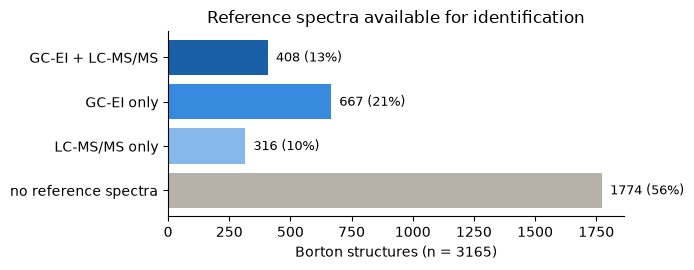

In [8]:
order = ["GC-EI + LC-MS/MS", "GC-EI only", "LC-MS/MS only", "no reference spectra"]
cnt = u["id_route"].value_counts().reindex(order).fillna(0)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(order[::-1], cnt[order[::-1]], color=["#B4B2A9", "#85B7EB", "#378ADD", "#185FA5"])
for y, v in enumerate(cnt[order[::-1]]): ax.text(v, y, f"  {int(v)} ({100*v/n:.0f}%)", va="center", fontsize=9)
ax.set_xlabel(f"Borton structures (n = {n})"); ax.set_title("Reference spectra available for identification")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout()
plt.savefig(OUT / "borton_ms_id_routes.png", dpi=150); plt.show()

## 6. Show the reference spectra for a compound
`ms_spectra.py` (written below) indexes every spectrum in the libraries once, by file position, so a compound's spectra load instantly. The index is cached in `ms_id_outputs/spectra_index.csv`. A **spectra card** shows one representative spectrum per technique:
- **GC-EI:** the entry with the most peaks, with its Kovats RI.
- **LC-MS/MS positive / negative:** [M+H]⁺ / [M−H]⁻ preferred, collision energy closest to 30, then most peaks. The precursor m/z is marked.

`show("…")` accepts a Borton name fragment, CAS, Borton ID or InChIKey. `list_spectra` lists every available spectrum, if you want a different one. The same module can be used in the Streamlit app (`st.pyplot(spectra_card(...))`).

In [9]:
%%writefile ms_spectra.py
"""Index MSP spectral libraries and draw reference spectra per compound (InChIKey first block).

Reusable from a notebook or a Streamlit app:
    idx = build_index(msp_files, cache_csv)          # once; cached
    table = list_spectra(idx, "FLKPEMZONWLCSK")      # what's available
    fig = spectra_card(idx, "FLKPEMZONWLCSK", title="Diethyl phthalate")
Only numpy, pandas and matplotlib are needed.
"""
from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd

_KEYS = {"NAME": "name", "INCHIKEY": "inchikey", "PRECURSORTYPE": "adduct", "PRECURSORMZ": "precursor_mz",
         "COLLISIONENERGY": "ce", "INSTRUMENTTYPE": "instrument", "IONMODE": "ionmode",
         "RETENTIONINDEX": "ri", "NUMPEAKS": "n_peaks"}


def _kind(path: Path) -> str:
    n = path.name.lower()
    if n.startswith("gcms") or "kovats" in n:
        return "EI"
    return "MSMS_neg" if "neg" in n else "MSMS_pos"


def build_index(msp_files, cache_csv=None):
    """One row per spectrum: file, byte offset, kind, ik1 and metadata. Cached as CSV and rebuilt
    automatically when a library file is newer than the cache or the file list changes."""
    msp_files = [Path(p) for p in msp_files]
    if cache_csv is not None:
        cache_csv = Path(cache_csv)
        if cache_csv.exists() and all(cache_csv.stat().st_mtime > p.stat().st_mtime for p in msp_files):
            idx = pd.read_csv(cache_csv, dtype={"ce": str, "adduct": str, "instrument": str})
            if set(idx["file"]) == {str(p) for p in msp_files}:
                return idx
    rows = []
    for p in msp_files:
        kind = _kind(p)
        with open(p, "rb") as f:
            cur, start, pos = {}, None, 0
            for raw in f:
                line = raw.decode("utf-8", "ignore")
                if not line.strip():
                    if cur:
                        rows.append({**cur, "file": str(p), "offset": start, "kind": kind}); cur = {}
                    start = None
                elif not line[0].isdigit():
                    if start is None:
                        start = pos
                    k, sep, v = line.partition(":")
                    if sep:
                        k = k.strip().upper().replace(" ", "").replace("_", "")
                        if k in _KEYS:
                            cur[_KEYS[k]] = v.strip()
                pos += len(raw)
            if cur:
                rows.append({**cur, "file": str(p), "offset": start, "kind": kind})
    idx = pd.DataFrame(rows)
    idx["ik1"] = idx["inchikey"].astype("string").str.split("-").str[0]
    idx["name"] = idx["name"].astype("string").str.split(";").str[0].str.strip()
    for c in ("precursor_mz", "ri", "n_peaks"):
        idx[c] = pd.to_numeric(idx.get(c), errors="coerce")
    idx.loc[idx["ri"] <= 0, "ri"] = np.nan
    idx["ce_num"] = pd.to_numeric(idx.get("ce").astype("string").str.extract(r"([\d.]+)")[0], errors="coerce")
    idx = idx.dropna(subset=["ik1"]).reset_index(drop=True)
    if cache_csv is not None:
        idx.to_csv(cache_csv, index=False)
    return idx


def read_peaks(file, offset):
    """Peaks (m/z, intensity) of the record starting at byte `offset`."""
    mz, it, in_peaks = [], [], False
    with open(file, "rb") as f:
        f.seek(int(offset))
        for raw in f:
            line = raw.decode("utf-8", "ignore").strip()
            if not line:
                break
            if in_peaks or line[0].isdigit():
                for a, b in re.findall(r"([\d.]+)[\s:]+([\d.eE+-]+)", line):
                    mz.append(float(a)); it.append(float(b))
            elif line.upper().replace(" ", "").startswith("NUMPEAKS"):
                in_peaks = True
    mz, it = np.array(mz), np.array(it)
    if it.size and it.max() > 0:
        it = 100 * it / it.max()
    return mz, it


def list_spectra(idx, ik1):
    cols = ["kind", "name", "adduct", "ce", "instrument", "precursor_mz", "ri", "n_peaks", "file", "offset"]
    return idx.loc[idx["ik1"] == ik1, [c for c in cols if c in idx]].reset_index(drop=True)


def pick_representative(sub, kind):
    """One spectrum per kind: EI -> most peaks; MS/MS -> preferred adduct ([M+H]+ / [M-H]-),
    collision energy closest to 30, then most peaks."""
    s = sub[sub["kind"] == kind]
    if s.empty:
        return None
    if kind == "EI":
        return s.sort_values("n_peaks", ascending=False).iloc[0]
    pref = "[M+H]+" if kind == "MSMS_pos" else "[M-H]-"
    s = s.assign(_a=(s["adduct"] != pref).astype(int), _c=(s["ce_num"] - 30).abs().fillna(99))
    return s.sort_values(["_a", "_c", "n_peaks"], ascending=[True, True, False]).iloc[0]


def plot_spectrum(ax, mz, it, title, precursor=None, n_labels=6, color="#185FA5"):
    ax.vlines(mz, 0, it, color=color, lw=1)
    for k in np.argsort(it)[::-1][:n_labels]:
        ax.text(mz[k], it[k] + 2, f"{mz[k]:.4g}", ha="center", fontsize=7)
    if precursor is not None and np.isfinite(precursor):
        ax.axvline(precursor, color="#BA7517", lw=0.8, ls="--")
    sig = mz[it >= 1] if (it >= 1).any() else mz
    hi = max(sig.max() if sig.size else 100, precursor if precursor is not None and np.isfinite(precursor) else 0)
    lo = sig.min() if sig.size else 0
    ax.set_xlim(max(0, lo - 0.08 * (hi - lo) - 5), hi + 0.08 * (hi - lo) + 5)
    ax.set_ylim(0, 115); ax.set_ylabel("rel. int. (%)"); ax.set_title(title, fontsize=9, loc="left")
    ax.spines[["top", "right"]].set_visible(False)


def spectra_card(idx, ik1, title=None, kinds=("EI", "MSMS_pos", "MSMS_neg")):
    """Figure with one representative spectrum per available kind. Returns None if nothing found."""
    import matplotlib.pyplot as plt
    sub = idx[idx["ik1"] == ik1]
    picks = [(k, pick_representative(sub, k)) for k in kinds]
    picks = [(k, r) for k, r in picks if r is not None]
    if not picks:
        return None
    fig, axes = plt.subplots(len(picks), 1, figsize=(7.5, 2.3 * len(picks)), squeeze=False)
    label = {"EI": "GC-EI (70 eV)", "MSMS_pos": "LC-MS/MS positive", "MSMS_neg": "LC-MS/MS negative"}
    colors = {"EI": "#185FA5", "MSMS_pos": "#0F6E56", "MSMS_neg": "#993C1D"}
    for ax, (k, r) in zip(axes[:, 0], picks):
        mz, it = read_peaks(r["file"], r["offset"])
        n_all = int((sub["kind"] == k).sum())
        bits = [label[k], f"{n_all} spectrum in library" if n_all == 1 else f"{n_all} spectra in library"]
        if k == "EI" and pd.notna(r.get("ri")): bits.append(f"RI {r['ri']:.0f}")
        if k != "EI":
            val = lambda x: str(x) if pd.notna(x) and str(x).strip() else ""
            ce = val(r.get("ce"))
            bits += [val(r.get("adduct")), f"CE {ce}" if ce else "CE not given", val(r.get("instrument"))]
        plot_spectrum(ax, mz, it, " · ".join(b for b in bits if b and b != "nan"),
                      precursor=r.get("precursor_mz") if k != "EI" else None, color=colors[k])
    axes[-1, 0].set_xlabel("m/z")
    fig.suptitle(title or ik1, fontsize=11, x=0.01, ha="left")
    fig.tight_layout()
    return fig

Overwriting ms_spectra.py


404562 spectra indexed: {'MSMS_pos': 322191, 'MSMS_neg': 54151, 'EI': 28220}
kind
EI           9
MSMS_neg    14
MSMS_pos    20


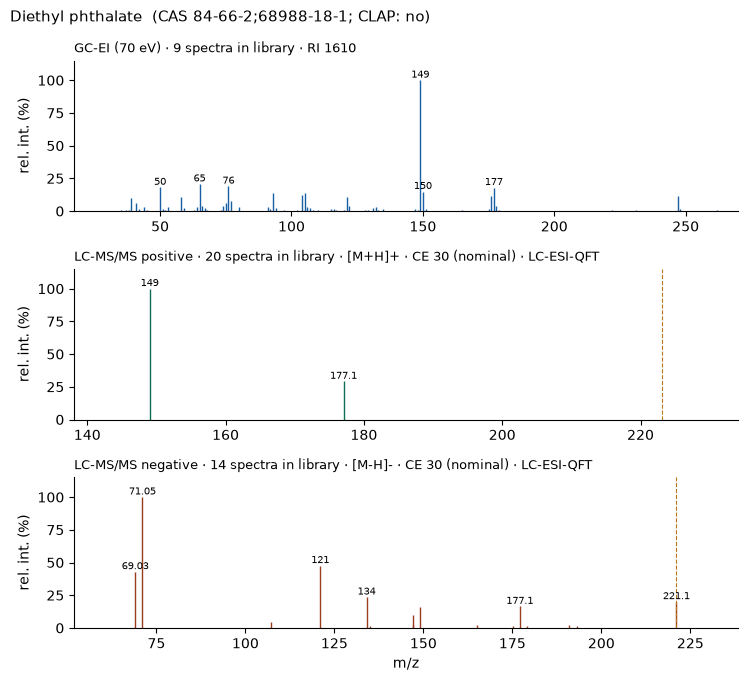

In [10]:
import importlib, sys, os; sys.path.insert(0, os.getcwd())
import ms_spectra as S; importlib.reload(S)
spec_idx = S.build_index(EI_MSP + MSMS_MSP, OUT / "spectra_index.csv")
print(f"{len(spec_idx)} spectra indexed:", spec_idx["kind"].value_counts().to_dict())

def find(query):
    q = str(query).strip()
    names = t["name"].fillna("").astype(str)
    cas = t["valid_cas"].fillna("").astype(str)
    m = (names.str.contains(q, case=False, regex=False) | (t["borton_id"] == q)
         | cas.apply(lambda v: q in [c.strip() for c in v.split(";")]) | (t["ik1"] == q[:14]))
    return t[m & t["ik1"].notna()].drop_duplicates("ik1")

def show(query, save=False):
    hits = find(query)
    if hits.empty:
        print("No Borton compound with a structure matches", repr(query)); return
    if len(hits) > 1:
        print(f"{len(hits)} matches; showing the first. Use a CAS or Borton ID to be specific:")
        print(hits[["borton_id", "name", "valid_cas", "ik1", "id_route"]].head(10).to_string(index=False))
    r = hits.iloc[0]
    print(S.list_spectra(spec_idx, r["ik1"]).drop(columns=["file", "offset"]).groupby("kind").size().to_string())
    title = f"{r['name']}  (CAS {r['valid_cas']}; CLAP: {r['clap_code'] if pd.notna(r['clap_code']) else 'no'})"
    fig = S.spectra_card(spec_idx, r["ik1"], title=title)
    if fig is None:
        print("No reference spectra in the libraries for", r["name"]); return
    if save:
        (OUT / "spectra_cards").mkdir(exist_ok=True)
        fig.savefig(OUT / "spectra_cards" / f"{r['ik1']}.png", dpi=150)
    plt.show()

show("Diethyl phthalate")

In [11]:
# Export cards for a set of compounds. Default: Borton compounds that are in CLAP and have reference spectra.
EXPORT = u[u["quant_CLAP"] & u["id_any"]]
(OUT / "spectra_cards").mkdir(exist_ok=True)
rows = []
for r in EXPORT.itertuples():
    fig = S.spectra_card(spec_idx, r.ik1, title=f"{r.name}  (CAS {r.valid_cas}; CLAP {r.clap_code})")
    if fig is None: continue
    fn = OUT / "spectra_cards" / f"{r.ik1}.png"; fig.savefig(fn, dpi=130); plt.close(fig)
    rows.append(dict(ik1=r.ik1, name=r.name, cas=r.valid_cas, clap_code=r.clap_code, card=fn.name))
pd.DataFrame(rows).to_csv(OUT / "spectra_cards" / "index.csv", index=False)
print(len(rows), "cards written to", OUT / "spectra_cards")

63 cards written to C:\Users\misak\Documents\Project\Hackathon\ms_id_outputs\spectra_cards


## Notes and caveats
- **Lower bound** until step 03 (PubChem) has resolved all Borton CAS numbers; rows without CAS need `--name-fallback`.
- **Matching on the first InChIKey block** ignores stereochemistry and charge state; salts and mixtures may be matched to their parent structure.
- **A spectrum ≠ an identification.** It is a reference that makes identification *possible*; confirmation still needs RI/RT agreement and ideally a standard.
- **MS/MS ion mode:** positive and negative MS-DIAL libraries are counted separately (`id_LC_pos`, `id_LC_neg`). MassSpecGym is counted as positive; check its adduct counts above.
- **Library quality varies.** Spectra are shown as deposited; some entries (e.g. an [M−H]− spectrum for a compound without an acidic H) deserve a second look before use.
- **Public libraries only.** NIST EI/MS/MS (licensed) would raise coverage, especially for polymer additives.
- Sources: Borton & Coleman, ALTEX 2025 (doi:10.14573/altex.2504231); MS-DIAL public libraries (RIKEN, prime.psc.riken.jp/compms/msdial); MassSpecGym (Bushuiev et al., NeurIPS 2024); FDA CLAP (RST24MC05.01); PlastChem (Wagner et al. 2024, doi:10.5281/zenodo.10701706); Stavitskaya et al. 2026 (doi:10.1016/j.yrtph.2026.106163).